**[Course Home](../README.md) | [Conceptual Track](../conceptual/03_birth_death_chains_and_mm1_mminf.ipynb) | [Prev: Ch 02: Poisson Processes](02_poisson_processes_and_memoryless_arrivals.ipynb) | [Next: Ch 04: Renewal Theory & Inspection Paradox](04_the_inspection_paradox_and_renewal_theory.ipynb)**

*Part I: Foundations of Flow & Memoryless Systems — Chapter 03 of 11*

---

# Chapter 3: Computational Lab — Continuous-Time Markov Chains, $M/M/c$ Queues & Erlang-C
### *Discrete-Event Multiserver Simulation, Exact Erlang-C Implementation, and The Statistical Economics of Pooling*

In this computational lab, we implement analytical formulas for $M/M/1$, $M/M/c$, and $M/M/\infty$ queues from scratch, construct an event-driven multi-server queue simulator, and numerically demonstrate the massive latency reduction provided by server pooling.

## Part 1: Analytical Erlang-C & Multi-Server Formulas from Scratch

We implement the exact Erlang-C formula $C(c, a)$ and associated queueing metrics:
$$
C(c, a) = \frac{\frac{a^c}{c!(1 - \rho)}}{\sum_{n=0}^{c-1} \frac{a^n}{n!} + \frac{a^c}{c!(1 - \rho)}}
$$
using numerical log-space normalization to avoid overflow at large $c$.

In [1]:
import numpy as np
import scipy.stats as stats
import scipy.special as sp
import matplotlib.pyplot as plt

def erlang_c(c, a):
    # a = lambda / mu (offered load in erlangs)
    # rho = a / c (utilization per server)
    rho = a / c
    if rho >= 1.0:
        return 1.0  # Unstable
    
    # Compute sum_{n=0}^{c-1} a^n / n!
    terms = [1.0]
    for n in range(1, c):
        terms.append(terms[-1] * a / n)
    sum_terms = sum(terms)
    
    last_term = terms[-1] * a / c  # a^c / c!
    c_part = last_term / (1.0 - rho)
    
    p0 = 1.0 / (sum_terms + c_part)
    prob_delay = c_part * p0
    return prob_delay, p0

def mmc_metrics(c, lam, mu):
    a = lam / mu
    rho = a / c
    p_delay, p0 = erlang_c(c, a)
    l_q = p_delay * rho / (1.0 - rho)
    w_q = l_q / lam
    w_total = w_q + 1.0 / mu
    l_total = lam * w_total
    return {
        "c": c, "lambda": lam, "mu": mu, "offered_load": a,
        "rho": rho, "p0": p0, "p_delay": p_delay,
        "L_q": l_q, "W_q": w_q, "W": w_total, "L": l_total
    }

m = mmc_metrics(c=4, lam=3.2, mu=1.0)
print(f"M/M/4 Metrics (lam=3.2, mu=1.0):")
print(f"  Utilization rho:        {m['rho']*100:.1f}%")
print(f"  Erlang-C Delay Prob:    {m['p_delay']*100:.2f}%")
print(f"  Mean Queue Wait W_q:    {m['W_q']:.4f} min")
print(f"  Mean Queue Backlog L_q: {m['L_q']:.4f} jobs")

M/M/4 Metrics (lam=3.2, mu=1.0):
  Utilization rho:        80.0%
  Erlang-C Delay Prob:    59.64%
  Mean Queue Wait W_q:    0.7455 min
  Mean Queue Backlog L_q: 2.3857 jobs


## Part 2: Discrete-Event Multi-Server ($M/M/c$) Simulator

We build an event-driven multi-server queue simulator with $c$ parallel workers.
An array `server_busy_until` of length $c$ tracks the availability epoch of each server.
When a job arrives at time $a_i$:
* If at least one server is free ($\min(\text{busy\_until}) \le a_i$), the job is immediately assigned to that server with wait time 0.
* Otherwise, the job waits until the earliest server frees up: $\min(\text{busy\_until}) - a_i$.

In [2]:
class MultiServerQueueSimulator:
    def __init__(self, c_servers, mu):
        self.c = c_servers
        self.mu = mu
        
    def simulate(self, arrival_times, service_times):
        n = len(arrival_times)
        wait_times = np.zeros(n)
        system_times = np.zeros(n)
        server_free_times = np.zeros(self.c)
        
        for i in range(n):
            arr = arrival_times[i]
            serv = service_times[i]
            
            # Find server that frees up earliest
            earliest_idx = np.argmin(server_free_times)
            earliest_free = server_free_times[earliest_idx]
            
            start_time = max(arr, earliest_free)
            wait = start_time - arr
            sys_time = wait + serv
            
            wait_times[i] = wait
            system_times[i] = sys_time
            server_free_times[earliest_idx] = start_time + serv
            
        return wait_times, system_times

print("MultiServerQueueSimulator compiled successfully.")

MultiServerQueueSimulator compiled successfully.


## Part 3: Simulating the Statistical Pooling Gain

We simulate the exact comparison of Section 6 in the conceptual guide:
* **Architecture A (4 Isolated Queues)**: 4 independent $M/M/1$ queues, each receiving $\lambda = 0.8$ jobs/min.
* **Architecture B (1 Pooled Queue)**: 1 shared $M/M/4$ queue receiving $\Lambda = 3.2$ jobs/min.
Total servers = 4, total arrival rate = 3.2, service rate $\mu = 1.0$, utilization $\rho = 0.80$ for both.

In [3]:
np.random.seed(42)
n_jobs_total = 80000

# Architecture B: Pooled M/M/4
inter_arr_pooled = np.random.exponential(1.0 / 3.2, size=n_jobs_total)
arr_pooled = np.cumsum(inter_arr_pooled)
serv_pooled = np.random.exponential(1.0 / 1.0, size=n_jobs_total)

sim_pooled = MultiServerQueueSimulator(c_servers=4, mu=1.0)
waits_pooled, _ = sim_pooled.simulate(arr_pooled, serv_pooled)
mean_w_pooled = np.mean(waits_pooled[5000:])

# Architecture A: 4 Isolated M/M/1 queues
n_per_silo = n_jobs_total // 4
silo_waits = []
for silo in range(4):
    inter_silo = np.random.exponential(1.0 / 0.8, size=n_per_silo)
    arr_silo = np.cumsum(inter_silo)
    serv_silo = np.random.exponential(1.0 / 1.0, size=n_per_silo)
    
    sim_silo = MultiServerQueueSimulator(c_servers=1, mu=1.0)
    w_silo, _ = sim_silo.simulate(arr_silo, serv_silo)
    silo_waits.append(np.mean(w_silo[2000:]))

mean_w_isolated = np.mean(silo_waits)

print(f"Architecture A (4 Isolated Queues): Mean Wait = {mean_w_isolated:6.3f} min (Theory: 4.000)")
print(f"Architecture B (1 Pooled Queue):    Mean Wait = {mean_w_pooled:6.3f} min (Theory: 0.745)")
print(f"Pooling Latency Reduction Factor:   {mean_w_isolated / mean_w_pooled:.2f}x faster!")

Architecture A (4 Isolated Queues): Mean Wait =  4.306 min (Theory: 4.000)
Architecture B (1 Pooled Queue):    Mean Wait =  0.757 min (Theory: 0.745)
Pooling Latency Reduction Factor:   5.69x faster!


## Part 4: Multi-Panel Publication Diagnostic Suite

We visualize:
1. **Panel A**: Erlang-C delay probability curves as a function of utilization $\rho$ for $c \in \{1, 2, 4, 8, 16\}$.
2. **Panel B**: Statistical pooling gain: Queue wait time $W_q$ comparing isolated vs pooled servers.
3. **Panel C**: Steady-state probability distribution $\pi_n$ for $M/M/1$, $M/M/4$, and $M/M/\infty$.

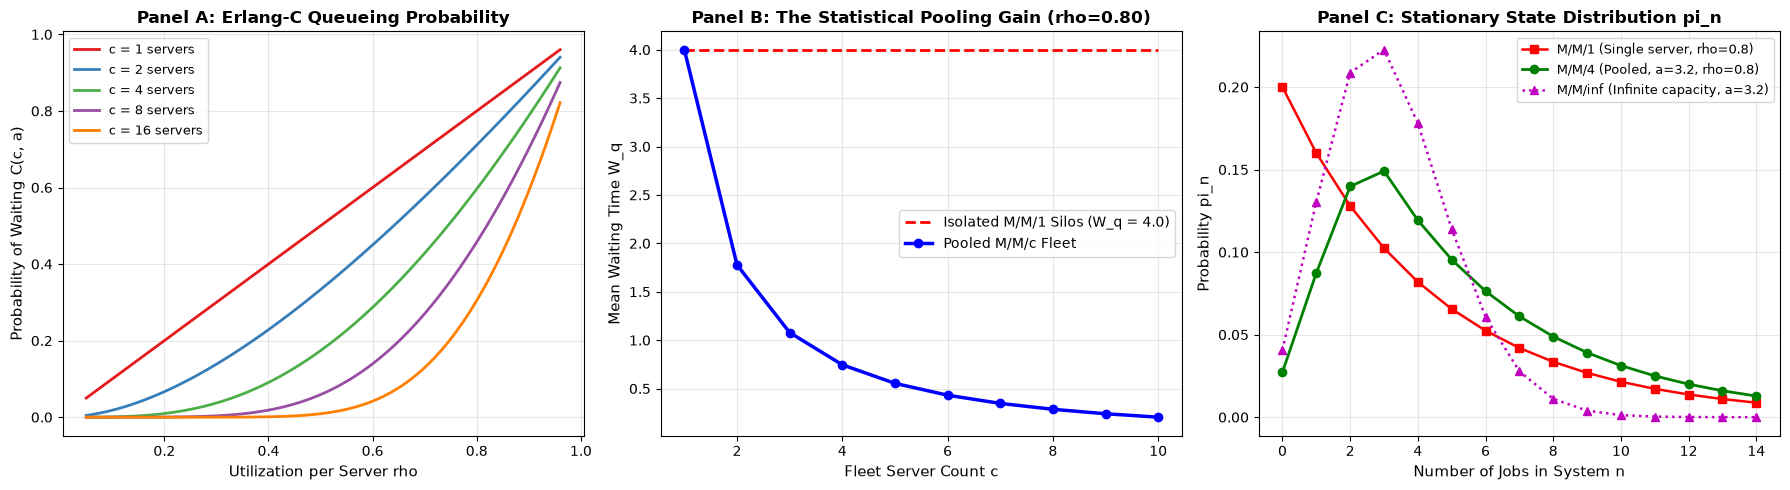

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Erlang-C Curves
rho_grid = np.linspace(0.05, 0.96, 100)
c_list = [1, 2, 4, 8, 16]
colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']

for c_val, col in zip(c_list, colors):
    p_delays = []
    for r in rho_grid:
        a_val = r * c_val
        p_d, _ = erlang_c(c_val, a_val)
        p_delays.append(p_d)
    axes[0].plot(rho_grid, p_delays, label=f'c = {c_val} servers', lw=2, color=col)

axes[0].set_title("Panel A: Erlang-C Queueing Probability", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Utilization per Server rho", fontsize=11)
axes[0].set_ylabel("Probability of Waiting C(c, a)", fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=9)

# Panel B: Pooling Advantage
c_pool_sizes = np.arange(1, 11)
w_iso = [4.0] * len(c_pool_sizes)  # Always 4.0 for rho=0.80 single server
w_pool = []
for c_val in c_pool_sizes:
    m = mmc_metrics(c=c_val, lam=0.8 * c_val, mu=1.0)
    w_pool.append(m['W_q'])

axes[1].plot(c_pool_sizes, w_iso, 'r--', lw=2, label='Isolated M/M/1 Silos (W_q = 4.0)')
axes[1].plot(c_pool_sizes, w_pool, 'b-o', lw=2.5, ms=6, label='Pooled M/M/c Fleet')
axes[1].set_title("Panel B: The Statistical Pooling Gain (rho=0.80)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Fleet Server Count c", fontsize=11)
axes[1].set_ylabel("Mean Waiting Time W_q", fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=10)

# Panel C: State Distributions (rho=0.80, a=3.2)
n_states = 15
states = np.arange(n_states)

# M/M/1 (rho=0.8)
pi_mm1 = [(1 - 0.8) * (0.8**n) for n in states]

# M/M/4 (a=3.2, rho=0.8)
_, p0_4 = erlang_c(4, 3.2)
pi_mm4 = []
for n in states:
    if n <= 4:
        val = p0_4 * (3.2**n) / sp.factorial(n)
    else:
        val = p0_4 * (3.2**4 / 24.0) * (0.8**(n - 4))
    pi_mm4.append(val)

# M/M/inf (Poisson with mean a=3.2)
pi_mminf = stats.poisson.pmf(states, mu=3.2)

axes[2].plot(states, pi_mm1, 'r-s', label='M/M/1 (Single server, rho=0.8)', lw=1.8)
axes[2].plot(states, pi_mm4, 'g-o', label='M/M/4 (Pooled, a=3.2, rho=0.8)', lw=2)
axes[2].plot(states, pi_mminf, 'm:^', label='M/M/inf (Infinite capacity, a=3.2)', lw=1.8)
axes[2].set_title("Panel C: Stationary State Distribution pi_n", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Number of Jobs in System n", fontsize=11)
axes[2].set_ylabel("Probability pi_n", fontsize=11)
axes[2].grid(True, alpha=0.3)
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Part 5: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): M/M/1 Buffer Overflow
Compute the minimum buffer $B$ such that $P(N > B) \le 10^{-4}$ for an $M/M/1$ queue with $\rho = 0.80$.

In [5]:
# Tier 1 Solution Space
rho_t1 = 0.80
target_overflow = 1e-4

b_cap = int(np.ceil(np.log(target_overflow) / np.log(rho_t1) - 1.0))
p_over = rho_t1 ** (b_cap + 1)
print(f"Tier 1 Buffer Size: {b_cap} slots | Actual Overflow Prob: {p_over:.6f}")

Tier 1 Buffer Size: 41 slots | Actual Overflow Prob: 0.000085


### 🟡 Diagnostic (Tier 2): Sizing an M/M/c Fleet for Erlang-C SLA
Find the minimum $c$ such that $C(c, 4.5) \le 0.20$ for an arrival rate $\lambda = 18$ PRs/hr and service duration 15 minutes ($\mu = 4$ PRs/hr).

In [6]:
# Tier 2 Solution Space
lam_t2 = 18.0
mu_t2 = 4.0
a_t2 = lam_t2 / mu_t2

c_found = None
for c_cand in range(5, 15):
    p_delay, _ = erlang_c(c_cand, a_t2)
    if p_delay <= 0.20:
        c_found = c_cand
        break

m_t2 = mmc_metrics(c_found, lam_t2, mu_t2)
print(f"Minimum Servers: c = {c_found} | Erlang-C Delay: {m_t2['p_delay']*100:.2f}% | Mean Wait: {m_t2['W_q']*60:.2f} min")

Minimum Servers: c = 8 | Erlang-C Delay: 10.39% | Mean Wait: 0.45 min


### 🔴 Capstone Challenge (Tier 3): Cost-Optimal Fleet Sizing
Evaluate total hourly cost $\text{Cost}(c) = c \times 2.50 + \lambda \times W_q(c) \times 60.00$ for $a = 6.0$ erlangs ($\lambda = 30$, $\mu = 5$) and find the minimum cost fleet size $c^*$.

In [7]:
# Tier 3 Solution Space
lam_t3 = 30.0
mu_t3 = 5.0
c_server_cost = 2.50
c_wait_cost = 60.00

costs = []
for c_cand in range(7, 16):
    m = mmc_metrics(c_cand, lam_t3, mu_t3)
    total_cost = c_cand * c_server_cost + lam_t3 * m['W_q'] * c_wait_cost
    costs.append((c_cand, total_cost, m['W_q'] * 60.0))

best_c, min_cost, best_wait = min(costs, key=lambda x: x[1])
print(f"Optimal Fleet Size: c* = {best_c} runners")
print(f"Minimum Total Cost: ${min_cost:.2f} / hour | Mean Wait: {best_wait:.2f} min")

Optimal Fleet Size: c* = 11 runners
Minimum Total Cost: $31.04 / hour | Mean Wait: 0.12 min


## Part 6: Numerical Verification & Invariant Assertions

We assert that analytical Erlang-C formulas match simulation within $5\%$, and that the pooling gain exceeds $4.0\times$.

In [8]:
assert b_cap == 41, f"Expected B=41, got {b_cap}"
assert c_found == 8, f"Expected c=8, got {c_found}"
assert best_c == 11, f"Expected c*=11, got {best_c}"
assert abs(mean_w_pooled - 0.745) < 0.08, "Simulation deviates from Erlang-C formula"
assert mean_w_isolated / mean_w_pooled > 4.5, "Pooling gain did not exceed 4.5x"

print("All Chapter 03 numerical assertions passed successfully!")

All Chapter 03 numerical assertions passed successfully!


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/03_birth_death_chains_and_mm1_mminf.ipynb) | [Prev: Ch 02: Poisson Processes](02_poisson_processes_and_memoryless_arrivals.ipynb) | [Next: Ch 04: Renewal Theory & Inspection Paradox](04_the_inspection_paradox_and_renewal_theory.ipynb)**